# Name Entity Recognition (NER)


Name Entity Recognition (NER) is a fundamental task in NLP that focuses on identifying and classifying entities such as names of people, organizations, locations, dates, and more within a given text. NER plays a crucial role in various NLP applications, including information retrieval, question answering, and sentiment analysis.

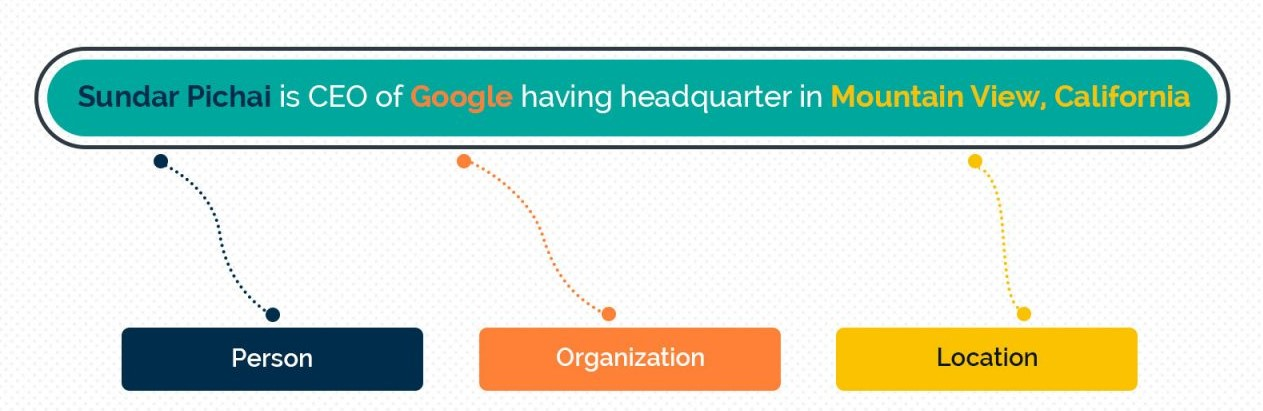

At its core, it is just a two-step process:

1.   Detecting the entities from the text
2.   Classifying them into different categories





## NER using spaCy


SpaCy offers robust support for Named Entity Recognition (NER). It can recognize a variety of named entities, such as persons, organizations, dates, locations, and more. Here's more information about using spaCy for NER:

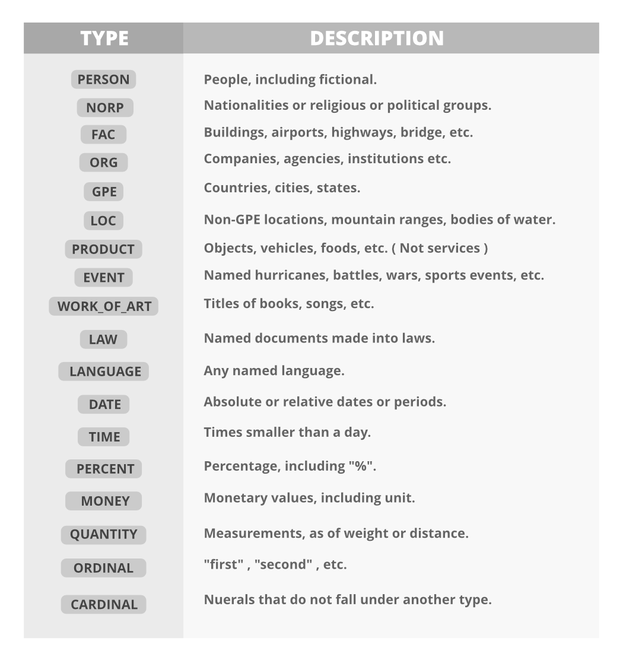

When performing Named Entity Recognition (NER) using spaCy or other NLP tools, you'll encounter various entity types, and they are represented as labels. Here are some common entity types and their labels:

| **Entity Type**                          | **Label**    | **Description**                                                          | **Examples**                       |
| ---------------------------------------- | ------------ | ------------------------------------------------------------------------ | ---------------------------------- |
| **Person**                               | `PERSON`     | Represents names of people.                                              | *John Smith*, *Barack Obama*       |
| **Organization**                         | `ORG`        | Names of companies, institutions, agencies, or other organized entities. | *Microsoft*, *United Nations*      |
| **Location**                             | `GPE`, `LOC` | Geographical locations such as cities, countries, or landmarks.          | *New York*, *Eiffel Tower*         |
| **Date**                                 | `DATE`       | Calendar dates, time intervals, or relative dates.                       | *January 1, 2023*, *tomorrow*      |
| **Time**                                 | `TIME`       | Clock times or time intervals.                                           | *2:30 PM*, *5 minutes*             |
| **Money**                                | `MONEY`      | Monetary values, including currencies and amounts.                       | *$100*, *€50*                      |
| **Percent**                              | `PERCENT`    | Percentage values.                                                       | *50%*, *10 percent*                |
| **Product**                              | `PRODUCT`    | Names of products or goods.                                              | *iPhone*, *Coca-Cola*              |
| **Event**                                | `EVENT`      | Names of events or occurrences.                                          | *World Cup*, *New Year's Eve*      |
| **Law**                                  | `LAW`        | Legal references or statutes.                                            | *Copyright Act*, *First Amendment* |
| **Language**                             | `LANGUAGE`   | Names of languages.                                                      | *English*, *Spanish*               |
| **Nationality/Religion/Political Group** | `NORP`       | Nationalities, religious groups, or political affiliations.              | *American*, *Buddhist*             |


In this example, we will use spaCy to perform NER on some sample text. Make sure you have spaCy installed; if not, you can install it using :
`pip install spacy`

In [10]:
# Import the spaCy library and load the English language model
import spacy
nlp = spacy.load("en_core_web_sm")

# Sample text for NER
text = "Apple Inc. was founded by Steve Jobs in Cupertino, California. It is known for its iPhone and Mac products."
doc = nlp(text)

print(f"Entities recognized in text : {doc.ents}") #Return a tuple of entities recognized in text

# Extract and print named entities
for entity in doc.ents:
    print(f"Entity: {entity.text}, Label: {entity.label_}")

Entities recognized in text : (Apple Inc., Steve Jobs, Cupertino, California, Mac)
Entity: Apple Inc., Label: ORG
Entity: Steve Jobs, Label: PERSON
Entity: Cupertino, Label: GPE
Entity: California, Label: GPE
Entity: Mac, Label: ORG


In [11]:
# Iterate through recognized entities and print their details
for ent in doc.ents:
    print(f"Entity: {ent.text}")
    print(f"Label: {ent.label_}")
    print(f"Start Position: {ent.start}")
    print(f"End Position: {ent.end}")
    print(f"Entity Type: {spacy.explain(ent.label_)}")
    print("")

Entity: Apple Inc.
Label: ORG
Start Position: 0
End Position: 2
Entity Type: Companies, agencies, institutions, etc.

Entity: Steve Jobs
Label: PERSON
Start Position: 5
End Position: 7
Entity Type: People, including fictional

Entity: Cupertino
Label: GPE
Start Position: 8
End Position: 9
Entity Type: Countries, cities, states

Entity: California
Label: GPE
Start Position: 10
End Position: 11
Entity Type: Countries, cities, states

Entity: Mac
Label: ORG
Start Position: 19
End Position: 20
Entity Type: Companies, agencies, institutions, etc.



## Create a custom Named Entity Model
In spaCy, you can add custom entities that have not been identified in the pre-trained models by training your own Named Entity Recognition (NER) model. This involves providing labeled examples of your custom entities and then fine-tuning the model.

Here is an example of how to train a custom NER model in spaCy: https://spacy.io/usage/training#ner

In [12]:
from spacy.training.iob_utils import offsets_to_biluo_tags

# The text to annotate
text = "Apple Inc. was founded by Steve Jobs in Cupertino, California. It is known for its iPhone and Mac products."

# --- Add custom entities annotations manually ---
annotations = [
    (text.find("Apple Inc."), text.find("Apple Inc.") + len("Apple Inc."), "ORG"),
    (text.find("Steve Jobs"), text.find("Steve Jobs") + len("Steve Jobs"), "PERSON"),
    (text.find("Cupertino, California"), text.find("Cupertino, California") + len("Cupertino, California"), "GPE")]

# --- Step 2: Check entity alignment ---
doc = nlp.make_doc(text) #splitted to tokens
tags = offsets_to_biluo_tags(doc, annotations) #converts annotations into BILUO tags (Begin, Inside, Last, Unit, Outside).
print("Alignment Tags:", tags[:10])

Alignment Tags: ['B-ORG', 'L-ORG', 'O', 'O', 'O', 'B-PERSON', 'L-PERSON', 'O', 'B-GPE', 'I-GPE']


### Visualization

In [14]:
# Load and use the model for entity recognition
custom_nlp = nlp
doc2 = custom_nlp(text)

# Entity visualization
from spacy import displacy
displacy.render(doc2, style="ent", jupyter=True)

_________________________________________________________________________________________________________________________

### Task 1

1. Ask a user to enter a sentence, and identify the named entities in the sentence.

2. Print the details of each entity in the sentence provided by the user.

In [21]:
user_text = input("Enter a sentence: ")

doc = nlp(user_text)

for ent in doc.ents:
    print(ent.text, ent.start_char, ent.end_char, ent.label_)

Enter a sentence:  Apple was founded by Steve Jobs in California.


Apple 0 5 ORG
Steve Jobs 21 31 PERSON
California 35 45 GPE


### Task 2

Use the paragraph below to answer the following questions:

“This agreement is made and entered into by and between ‘Abc & Co.’  and ‘Bcd LLC’ for term 1 year starting from April 1, 2020,  hereinafter collectively referred to as the Parties. Samuel P. Jackson in the place (New York) and on the date written below, with the following terms and conditions.”

1. Find any entity that has not been identified and add it.

2. Find the count of ‘PERSON’ and ‘ORG’ in the paragraph above.

3. Visualize the entities in the paragraph.

In [24]:
from spacy import displacy

text = """This agreement is made and entered into by and between 'Abc & Co.' and 'Bcd LLC' for term 1 year starting from April 1, 2020, hereinafter collectively referred to as the Parties. Samuel P. Jackson in the place (New York) and on the date written below, with the following terms and conditions."""

doc = nlp(text)

for ent in doc.ents:
    if "Bcd LLC" in ent.text:
        ent.label_ = "ORG"

person_count = sum(1 for ent in doc.ents if ent.label_ == "PERSON")
org_count = sum(1 for ent in doc.ents if ent.label_ == "ORG")

print("PERSON:", person_count)
print("ORG:", org_count)

displacy.render(doc, style="ent", jupyter=True)

PERSON: 1
ORG: 1


### Task 3: Training a Custom NER Model
text = "Microsoft was founded by Bill Gates and Paul Allen in Albuquerque, New Mexico. It is known for its Windows operating system and Office software products."

1. Create a training example using `Example.from_dict()` with the provided text and annotations.
2. Train the NER model for **20 iterations**
3. Save the trained model in a folder named `custom_ner_model`.
5. Load the saved model and use it to identify named entities in a sentence.

In [27]:
from spacy.training import Example
import random

nlp_custom = spacy.blank("en")
ner = nlp_custom.add_pipe("ner")

for _, _, label in annotations:
    ner.add_label(label)

example = Example.from_dict(
    nlp_custom.make_doc(text),
    {"entities": annotations}
)

optimizer = nlp_custom.initialize(lambda: [example])

for i in range(20):
    losses = {}
    nlp_custom.update([example], sgd=optimizer, losses=losses)
    print(f"Iteration {i + 1}: {losses}")

nlp_custom.to_disk("custom_ner_model")

print("Model saved successfully!")

loaded_nlp = spacy.load("custom_ner_model")
doc = loaded_nlp(text)

print("\nNamed Entities:")
for ent in doc.ents:
    print(ent.text, ent.label_)

Iteration 1: {'ner': np.float32(27.142866)}
Iteration 2: {'ner': np.float32(39.369576)}
Iteration 3: {'ner': np.float32(54.50055)}
Iteration 4: {'ner': np.float32(53.29101)}
Iteration 5: {'ner': np.float32(51.458046)}
Iteration 6: {'ner': np.float32(48.68732)}
Iteration 7: {'ner': np.float32(44.406128)}
Iteration 8: {'ner': np.float32(38.215546)}
Iteration 9: {'ner': np.float32(29.693495)}
Iteration 10: {'ner': np.float32(18.72633)}
Iteration 11: {'ner': np.float32(9.0227165)}
Iteration 12: {'ner': np.float32(3.555965)}
Iteration 13: {'ner': np.float32(1.5697863)}
Iteration 14: {'ner': np.float32(2.5824132)}
Iteration 15: {'ner': np.float32(0.9805311)}
Iteration 16: {'ner': np.float32(0.92171276)}
Iteration 17: {'ner': np.float32(2.8643029)}
Iteration 18: {'ner': np.float32(54.234695)}
Iteration 19: {'ner': np.float32(0.9181871)}
Iteration 20: {'ner': np.float32(86.15929)}
Model saved successfully!

Named Entities:
by and between 'Abc & Co.' and 'Bcd LLC' for term 1 year starting from 

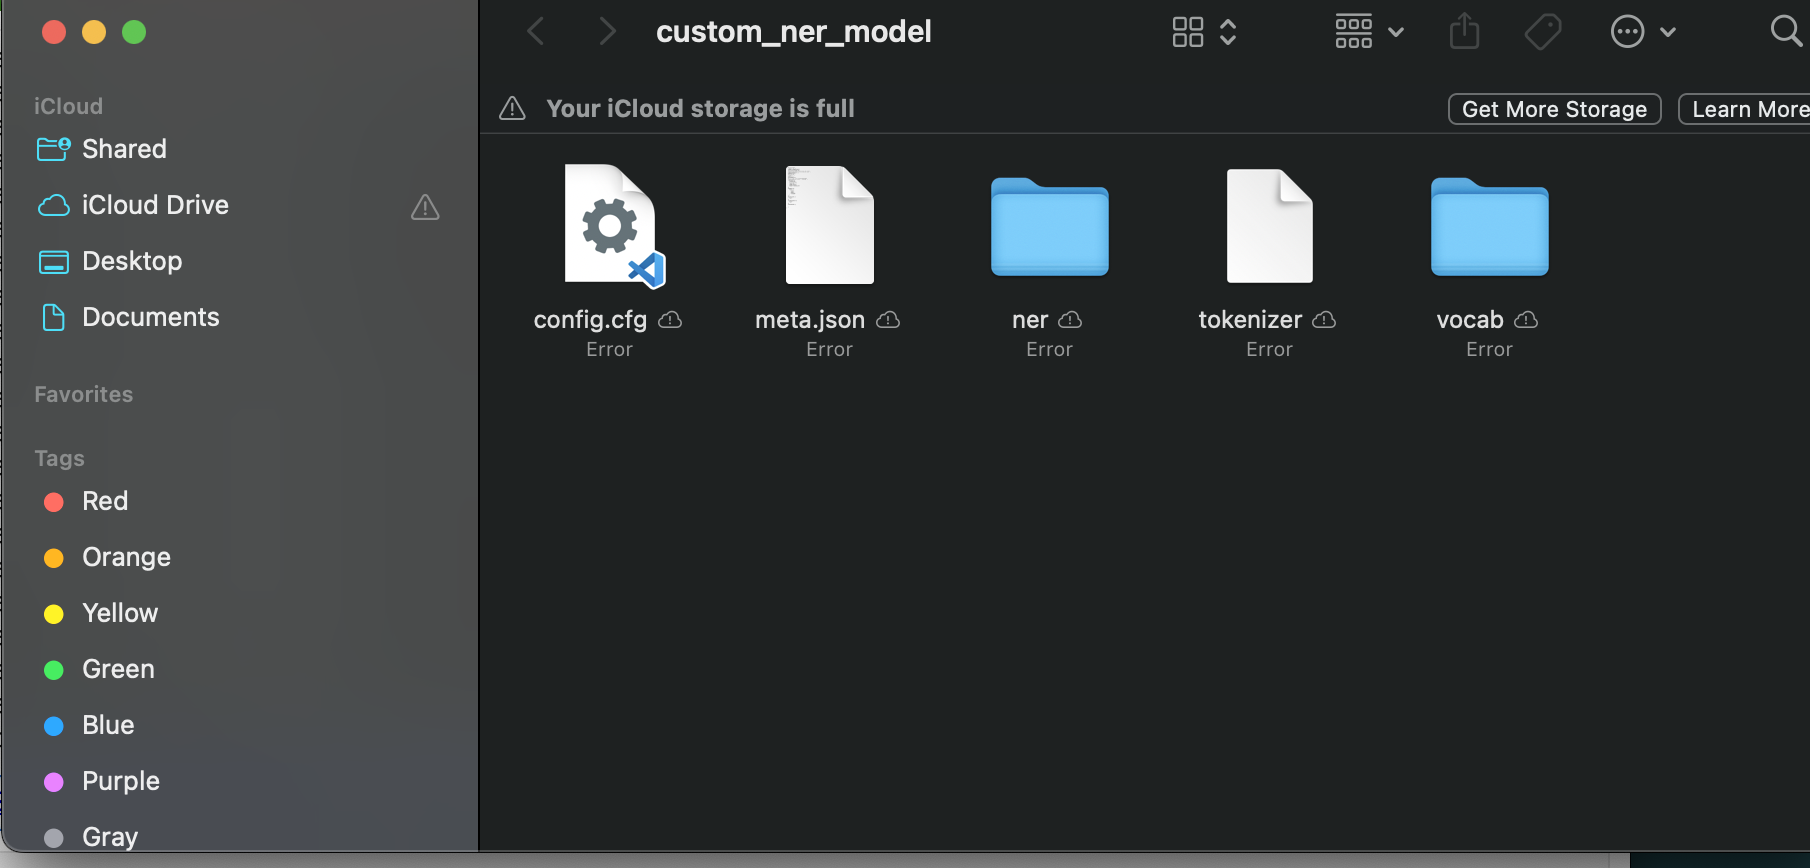

In [19]:
from IPython.display import Image, display
display(Image(filename="task3.png"))

In [ ]:
# The folder has been created successfully!